# 05 - Time-Series Models (Prophet & ARIMA) and Final Model Comparison
Classic time-series models only see the AQI history (no weather features), so they are a useful contrast to the feature-based ML models.

**Fair evaluation:** rolling-origin. Every `STEP` days in the test period we refit on the data available *at that time*, forecast the next 3 days, and compare with what really happened. All models are scored on the **same origins**.

> This notebook takes a few minutes (it refits many models). Increase `STEP` to run faster.

In [2]:
%pip install prophet statsmodels

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   --- ------------------------------------ 1.0/12.1 MB 8.5 MB/s eta 0:00:02
   --- ------------------------------------ 1.0/12.1 MB 8.5 MB/s eta 0:00:02
   ------ --------------------------------- 2.1/12.1 MB 3.3 MB/s eta 0:00:04
   ------------- -------------------------- 4.2/12.1 MB 5.3 MB/s eta 0:00:02
   ----------------- ---------------------- 5.2/12.1 MB 5.0 MB/s eta 0:00:02
   ----------------- ---------------------- 5.2/12.1 MB 5.0 MB/s eta 0:00:02
   ----------------- ---------------------- 5.2/12.1 MB 5.0 MB/s eta 0:00:02
   -------------------- ------------------- 6.3/12.1 MB 3.8 MB/s eta 0:00:02
   -------------------- ------------------- 6.3/12.1 MB 3.8 MB/s eta 0:00:02
   ------------------------ --------------- 7.3/12.1 MB 3.6 MB/s eta 0:00:02
   --------------------------- ------------ 8.4/12.1 MB 3.6 MB/s eta 0:00:02
   ------------------------------- -------- 9.4/12.1 MB 3.8 MB/s eta 0:00:01
   ---

In [1]:
import logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from utils import *

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)

STEP = 7          # forecast origin every 7 days
HISTORY = 1095    # use the latest 3 years for each refit

clean = pd.read_csv(CLEAN_PATH, index_col=0, parse_dates=True)
aqi = clean["AQI"].dropna()
ml_preds = pd.read_csv(RESULTS_DIR / "test_predictions.csv", parse_dates=["date"])

origins = sorted(ml_preds["date"].unique())[::STEP]
print(len(origins), "forecast origins")

52 forecast origins


In [2]:
records = []
for i, o in enumerate(origins):
    o = pd.Timestamp(o)
    hist = aqi.loc[:o].iloc[-HISTORY:]

    # ARIMA
    try:
        arima_fc = ARIMA(hist.values, order=(2, 0, 1)).fit().forecast(max(HORIZONS))
    except Exception:
        arima_fc = np.full(max(HORIZONS), hist.iloc[-1])

    # Prophet
    m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    m.fit(pd.DataFrame({"ds": hist.index, "y": hist.values}))
    fut = m.make_future_dataframe(periods=max(HORIZONS))
    prophet_fc = m.predict(fut)["yhat"].values[-max(HORIZONS):]

    for h in HORIZONS:
        records.append({"date": o, "horizon": h,
                        "ARIMA": arima_fc[h - 1], "Prophet": prophet_fc[h - 1]})
    if (i + 1) % 10 == 0:
        print(f"{i + 1}/{len(origins)} origins done")

ts_preds = pd.DataFrame(records)
ts_preds.head()

00:36:31 - cmdstanpy - INFO - Chain [1] start processing
00:36:32 - cmdstanpy - INFO - Chain [1] done processing
00:36:35 - cmdstanpy - INFO - Chain [1] start processing
00:36:35 - cmdstanpy - INFO - Chain [1] done processing
00:36:37 - cmdstanpy - INFO - Chain [1] start processing
00:36:37 - cmdstanpy - INFO - Chain [1] done processing
00:36:39 - cmdstanpy - INFO - Chain [1] start processing
00:36:39 - cmdstanpy - INFO - Chain [1] done processing
00:36:41 - cmdstanpy - INFO - Chain [1] start processing
00:36:41 - cmdstanpy - INFO - Chain [1] done processing
00:36:43 - cmdstanpy - INFO - Chain [1] start processing
00:36:44 - cmdstanpy - INFO - Chain [1] done processing
00:36:46 - cmdstanpy - INFO - Chain [1] start processing
00:36:46 - cmdstanpy - INFO - Chain [1] done processing
00:36:48 - cmdstanpy - INFO - Chain [1] start processing
00:36:49 - cmdstanpy - INFO - Chain [1] done processing
00:36:50 - cmdstanpy - INFO - Chain [1] start processing
00:36:51 - cmdstanpy - INFO - Chain [1]

10/52 origins done


00:36:55 - cmdstanpy - INFO - Chain [1] start processing
00:36:55 - cmdstanpy - INFO - Chain [1] done processing
00:36:57 - cmdstanpy - INFO - Chain [1] start processing
00:36:57 - cmdstanpy - INFO - Chain [1] done processing
00:36:59 - cmdstanpy - INFO - Chain [1] start processing
00:36:59 - cmdstanpy - INFO - Chain [1] done processing
00:37:01 - cmdstanpy - INFO - Chain [1] start processing
00:37:02 - cmdstanpy - INFO - Chain [1] done processing
00:37:04 - cmdstanpy - INFO - Chain [1] start processing
00:37:04 - cmdstanpy - INFO - Chain [1] done processing
00:37:06 - cmdstanpy - INFO - Chain [1] start processing
00:37:06 - cmdstanpy - INFO - Chain [1] done processing
00:37:08 - cmdstanpy - INFO - Chain [1] start processing
00:37:08 - cmdstanpy - INFO - Chain [1] done processing
00:37:10 - cmdstanpy - INFO - Chain [1] start processing
00:37:10 - cmdstanpy - INFO - Chain [1] done processing
00:37:12 - cmdstanpy - INFO - Chain [1] start processing
00:37:13 - cmdstanpy - INFO - Chain [1]

20/52 origins done


00:37:16 - cmdstanpy - INFO - Chain [1] start processing
00:37:17 - cmdstanpy - INFO - Chain [1] done processing
00:37:19 - cmdstanpy - INFO - Chain [1] start processing
00:37:19 - cmdstanpy - INFO - Chain [1] done processing
00:37:21 - cmdstanpy - INFO - Chain [1] start processing
00:37:21 - cmdstanpy - INFO - Chain [1] done processing
00:37:23 - cmdstanpy - INFO - Chain [1] start processing
00:37:24 - cmdstanpy - INFO - Chain [1] done processing
00:37:26 - cmdstanpy - INFO - Chain [1] start processing
00:37:26 - cmdstanpy - INFO - Chain [1] done processing
00:37:28 - cmdstanpy - INFO - Chain [1] start processing
00:37:28 - cmdstanpy - INFO - Chain [1] done processing
00:37:30 - cmdstanpy - INFO - Chain [1] start processing
00:37:30 - cmdstanpy - INFO - Chain [1] done processing
00:37:32 - cmdstanpy - INFO - Chain [1] start processing
00:37:32 - cmdstanpy - INFO - Chain [1] done processing
00:37:34 - cmdstanpy - INFO - Chain [1] start processing
00:37:35 - cmdstanpy - INFO - Chain [1]

30/52 origins done


... (2 outputs left out)

00:38:01 - cmdstanpy - INFO - Chain [1] start processing
00:38:01 - cmdstanpy - INFO - Chain [1] done processing
00:38:03 - cmdstanpy - INFO - Chain [1] start processing
00:38:03 - cmdstanpy - INFO - Chain [1] done processing
00:38:06 - cmdstanpy - INFO - Chain [1] start processing
00:38:06 - cmdstanpy - INFO - Chain [1] done processing
00:38:08 - cmdstanpy - INFO - Chain [1] start processing
00:38:08 - cmdstanpy - INFO - Chain [1] done processing
00:38:10 - cmdstanpy - INFO - Chain [1] start processing
00:38:11 - cmdstanpy - INFO - Chain [1] done processing
00:38:13 - cmdstanpy - INFO - Chain [1] start processing
00:38:13 - cmdstanpy - INFO - Chain [1] done processing
00:38:15 - cmdstanpy - INFO - Chain [1] start processing
00:38:15 - cmdstanpy - INFO - Chain [1] done processing
00:38:17 - cmdstanpy - INFO - Chain [1] start processing
00:38:17 - cmdstanpy - INFO - Chain [1] done processing
00:38:19 - cmdstanpy - INFO - Chain [1] start processing
00:38:19 - cmdstanpy - INFO - Chain [1]

50/52 origins done


00:38:24 - cmdstanpy - INFO - Chain [1] start processing
00:38:24 - cmdstanpy - INFO - Chain [1] done processing
00:38:26 - cmdstanpy - INFO - Chain [1] start processing
00:38:26 - cmdstanpy - INFO - Chain [1] done processing


,date,horizon,ARIMA,Prophet
0,2019-07-01,1,195.652305,95.776178
1,2019-07-01,2,205.764895,94.214018
2,2019-07-01,3,209.409122,92.315792
3,2019-07-08,1,143.709654,74.121318
4,2019-07-08,2,155.155922,74.610453


## Final comparison on identical forecast origins

In [3]:
comp = ml_preds.merge(ts_preds, on=["date", "horizon"], how="inner")
models = ["Persistence", "Ridge", "RandomForest", "XGBoost", "ARIMA", "Prophet"]

rows = []
for h in HORIZONS:
    d = comp[comp.horizon == h]
    for m_ in models:
        rows.append({"horizon": h, "model": m_,
                     "MAE": mean_absolute_error(d["y_true"], d[m_]),
                     "RMSE": np.sqrt(mean_squared_error(d["y_true"], d[m_]))})
final = pd.DataFrame(rows)
final["MAE vs persistence (%)"] = final.apply(
    lambda r: 100 * (1 - r["MAE"] / final[(final.horizon == r["horizon"]) &
                                           (final.model == "Persistence")]["MAE"].iloc[0]), axis=1)
final = final.round(2)
final.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print("Number of origins compared:", comp["date"].nunique())
final.pivot(index="model", columns="horizon", values="MAE").loc[models]

Number of origins compared: 52


horizon,1,2,3
model,,,
Persistence,28.67,46.10,60.17
Ridge,27.61,45.34,57.06
RandomForest,23.29,43.88,67.17
XGBoost,24.44,44.29,71.93
ARIMA,26.06,44.97,59.69
Prophet,47.22,57.01,49.83


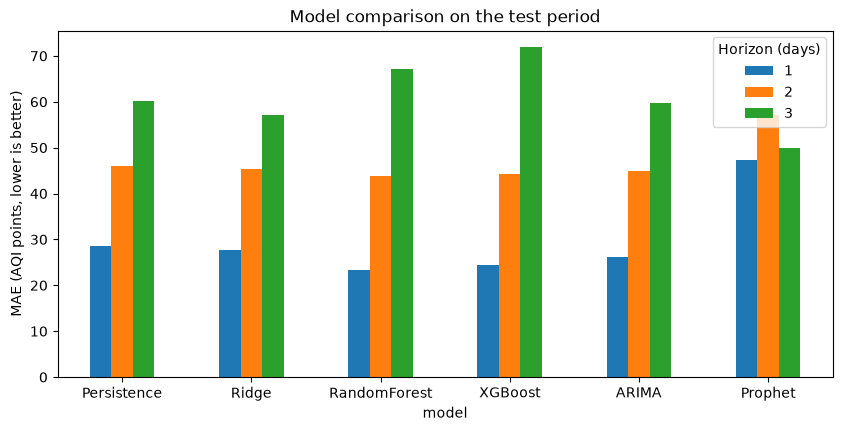

In [4]:
pivot = final.pivot(index="model", columns="horizon", values="MAE").loc[models]
ax = pivot.plot.bar(figsize=(10, 4.5), rot=0)
ax.set_ylabel("MAE (AQI points, lower is better)")
ax.set_title("Model comparison on the test period")
ax.legend(title="Horizon (days)")
plt.savefig(FIG_DIR / "model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

### How to interpret this (write this in your report)
* Compare every model with **Persistence**. A model that does not beat it is not adding value.
* ARIMA/Prophet generally struggle with sudden pollution spikes because they do not see weather or pollutant features.
* Errors grow with the horizon - that is expected and is why the dashboard shows a widening uncertainty band.